In [3]:
pip install pandas matplotlib statsmodels openpyxl

Jumlah data: 75 minggu (2026-08-30 s/d 2028-01-30)


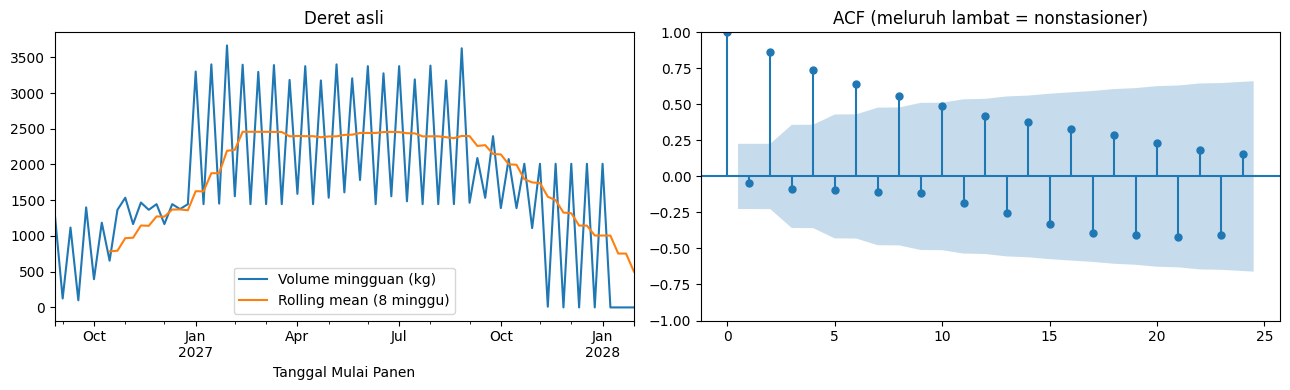

ADF p-value = 0.9121 -> NONSTASIONER


In [6]:
"""
Langkah 1: memastikan data TIDAK STASIONER
Sheet : 4_Jadwal_Tanam_Panen
Deret : volume target panen (kg) dari batch yang mulai panen, per minggu
Install: pip install pandas matplotlib statsmodels openpyxl
"""
import warnings
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf

warnings.filterwarnings("ignore")
FILE = "Rancangan_Keberlanjutan_Rantai_Pasok_Pasar_Tani.xlsx"
ALPHA = 0.05

# 1. Bangun deret waktu (hanya baris bersatuan kg)
df = pd.read_excel(FILE, sheet_name="4_Jadwal_Tanam_Panen")
df["Tanggal Mulai Panen"] = pd.to_datetime(df["Tanggal Mulai Panen"])
df["kg"] = (df["Target Panen Harian"].astype(str).str.lower()
              .str.extract(r"(\d+[.,]?\d*)\s*kg")[0]
              .str.replace(",", ".").astype(float))
y = (df.dropna(subset=["kg"]).set_index("Tanggal Mulai Panen")["kg"]
       .resample("W").sum())
print(f"Jumlah data: {len(y)} minggu ({y.index.min().date()} s/d {y.index.max().date()})")

# 2. Plot: deret asli + rolling mean + ACF
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
y.plot(ax=ax[0], label="Volume mingguan (kg)")
y.rolling(8).mean().plot(ax=ax[0], label="Rolling mean (8 minggu)")
ax[0].set_title("Deret asli"); ax[0].legend()
plot_acf(y, lags=24, ax=ax[1]); ax[1].set_title("ACF (meluruh lambat = nonstasioner)")
plt.tight_layout(); plt.savefig("cek_stasioneritas.png", dpi=150); plt.show()

# 3. Uji ADF (H0: nonstasioner; p >= 0,05 -> nonstasioner)
adf_p = adfuller(y, autolag="AIC")[1]
print(f"ADF p-value = {adf_p:.4f} -> {'stasioner' if adf_p < ALPHA else 'NONSTASIONER'}")